# KSI crash model: midterm results

Which NYC streets will have crashes that kill or seriously injure someone (KSI), and what about a site's design drives that risk? This notebook fits one negative binomial count model to every intersection and street block in the city and tests it on 2023–2025.

| Choice | Standard (defaults in `preprocessing/config.py`, `validation/validate.py`) |
|---|---|
| Crashes | NYPD crashes, geocoded in NYC, joined to persons and vehicles |
| KSI | Proxy from injury complaint and emotional status; only years under the post-2019 coding |
| Sites | 46,896 LION intersections plus 118,778 street blocks for crashes >100 ft from an intersection (99.4% of crashes assigned) |
| Features | Crash history, crash types and a no-history flag over the 3 years before each prediction year; site type; road features from the LION release in effect then (21d–25d) |
| Test | Train on prediction year 2022, score each site's total KSI over 2023–25 |
| Comparison | Picking sites at random |

In [1]:
import logging
import sys
import warnings
from pathlib import Path

sys.path.append("..")
warnings.filterwarnings("ignore", category=RuntimeWarning)
logging.getLogger().setLevel(logging.WARNING)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter, NullFormatter, PercentFormatter

from data.download import download_lion
from model.count_models import HistoryRanker, NegativeBinomialModel
from preprocessing.config import RoadwayConfig, SiteConfig
from preprocessing.crashes import load_crashes
from preprocessing.panel import FEATURE_SETS, load_panel
from preprocessing.roadway import (
    add_roadway_features,
    load_roadway_features,
    load_roadway_features_by_year,
)
from validation.validate import ValidationConfig, calibration_table, pooled_holdout, top_k_capture
from viz.style import COMPARISON, FULL_WIDTH, INK, INK_2, MODEL, MUTED, SURFACE, THIRD, use_style

use_style()
OUT = Path("outputs/ksi_model")
OUT.mkdir(parents=True, exist_ok=True)
SOURCE = "Source: NYPD Motor Vehicle Collisions; DCP LION."
TEST_YEARS = ValidationConfig().test_years


def source(fig, text=SOURCE):
    """Source line under the lowest drawn element (tick and axis labels)."""
    fig.canvas.draw()
    bottom = fig.get_tightbbox(fig.canvas.get_renderer()).y0 / fig.get_figheight()
    fig.text(0.0, bottom - 0.03, text, fontsize=7.5, color=MUTED, ha="left", va="top")


def save(fig, name):
    fig.savefig(OUT / f"{name}.png")


for _, release in RoadwayConfig().release_by_year:  # year-matched LION, ~5 s each once
    download_lion(release)

## 1. Who is hurt, and where

In [2]:
crashes = load_crashes()
crashes = crashes[crashes["crash_date"].dt.year.between(2019, 2025)]


def n(col):
    return crashes[col].fillna(0)


ped = n("number_of_pedestrians_injured") + n("number_of_pedestrians_killed") > 0
cyc = n("number_of_cyclist_injured") + n("number_of_cyclist_killed") > 0
road_user = np.select([ped, cyc], ["Pedestrian hurt", "Cyclist hurt"], "Motorists only")
order = ["Pedestrian hurt", "Cyclist hurt", "Motorists only"]
who = pd.DataFrame(
    {
        "KSI crashes": pd.Series(road_user[crashes["ksi"]]).value_counts(normalize=True),
        "All crashes": pd.Series(road_user).value_counts(normalize=True),
    }
).loc[order]
who.round(3)

,KSI crashes,All crashes
Pedestrian hurt,0.323,0.076
Cyclist hurt,0.159,0.045
Motorists only,0.518,0.879


In [3]:
panel, scoring, sites = load_panel()
roadway = load_roadway_features_by_year(sites)
panel = add_roadway_features(panel, roadway)

in_years = crashes["crash_date"].dt.year.between(panel["year"].min(), panel["year"].max())
ksi_total = int(crashes.loc[in_years, "ksi"].sum())
by_type = panel.groupby("midblock")["ksi"].sum()
where = pd.Series(
    {
        "Intersections": by_type[0],
        "Mid-block": by_type[1],
        "Not assigned": ksi_total - by_type.sum(),
    }
) / ksi_total
print(f"{len(sites):,} sites ({sites['midblock'].sum():,} mid-block); {ksi_total:,} KSI crashes 2022–25")
where.round(3)

165,674 sites (118,778 mid-block); 10,809 KSI crashes 2022–25


Intersections    0.804
Mid-block        0.188
Not assigned     0.008
dtype: float64

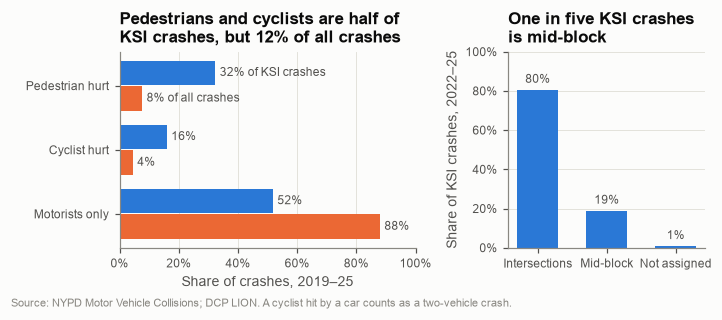

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(FULL_WIDTH, 2.8), gridspec_kw={"width_ratios": [1.5, 1]})
y = np.arange(len(order))
series = [("KSI crashes", "of KSI crashes", MODEL), ("All crashes", "of all crashes", COMPARISON)]
for offset, (col, name, color) in zip([-0.2, 0.2], series):
    bars = ax1.barh(y + offset, who[col], height=0.38, color=color)
    # name each series once, on the first row, instead of a legend
    labels = [f"{v:.0%}" + (f" {name}" if i == 0 else "") for i, v in enumerate(who[col])]
    ax1.bar_label(bars, labels=labels, padding=3, color=INK_2, fontsize=8)
ax1.set_yticks(y, order)
ax1.invert_yaxis()
ax1.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax1.set(xlabel="Share of crashes, 2019–25", xlim=(0, 1))
ax1.grid(axis="y", visible=False)
ax1.set_title("Pedestrians and cyclists are half of\nKSI crashes, but 12% of all crashes")

bars = ax2.bar(where.index, where.values, color=MODEL, width=0.6)
ax2.bar_label(bars, labels=[f"{v:.0%}" for v in where], padding=3, color=INK_2, fontsize=8)
ax2.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax2.set(ylabel="Share of KSI crashes, 2022–25", ylim=(0, 1))
ax2.grid(axis="x", visible=False)
ax2.set_title("One in five KSI crashes\nis mid-block")
fig.tight_layout()
source(fig, SOURCE + " A cyclist hit by a car counts as a two-vehicle crash.")
save(fig, "1_who_and_where")

**Takeaways.** Pedestrians and cyclists are about half of KSI crashes but an eighth of all crashes, so measures that protect them (crossings, protected lanes, speed) matter most. One in five KSI crashes happens mid-block, away from any intersection, which is why sites include street blocks and not only intersections. Mid-block locations are where speed cameras can sit; red-light cameras need an intersection.

## 2. What's in the model

Every input comes from public data. Crash records are NYC Open Data; street design is the Department of City Planning's LION street network.

| Dataset | Source | Used for |
|---|---|---|
| Motor Vehicle Collisions – Crashes | NYC Open Data `h9gi-nx95` | Date, time, location, injury and death counts, contributing factors |
| Motor Vehicle Collisions – Person | NYC Open Data `f55k-p6yu` | Injury complaint and emotional status (the KSI proxy) |
| Motor Vehicle Collisions – Vehicles | NYC Open Data `bm4k-52h4` | Point of impact (crash types) |
| LION street network | DCP, releases 21d–25d (road features) and 26c (site locations) | Sites, intersections and road design |

**Outcome: KSI crashes** at the site in the prediction year. A crash is KSI if anyone died, or if an injured person's complaint is severe (fracture, internal injury, severe bleeding or lacerations, crush injury, amputation, paralysis, moderate or severe burn, concussion) or their emotional status is unconscious, semiconscious or apparent death. Open data has no "serious injury" field, so this is a proxy (`CrashConfig`).

**Variables in the standard model.** Crash counts sum the 3 years before the prediction year and enter as log(1 + count), so a doubling has a constant effect. Road features come from the LION release in effect on January 1 of the prediction year and describe streets within 100 ft of the site's point. The model also has year fixed effects.

| Group | Variable | Definition | Derived from |
|---|---|---|---|
| Crash history | Property-damage-only crashes | No one injured or killed | Crashes |
| | Injury crashes (not KSI) | Someone injured, no KSI | Crashes, Person |
| | KSI crashes without a death | KSI by the proxy above, no one killed | Person |
| | Fatal crashes | Anyone killed | Crashes |
| | Pedestrians hurt | Pedestrians injured or killed | Crashes |
| | Cyclists hurt | Cyclists injured or killed | Crashes |
| | No crashes in 3 years | 0/1; separates "no history" from "safe" | Crashes |
| Crash types | Red-light running | Any vehicle's contributing factor is "Traffic Control Disregarded" (also covers stop signs) | Crashes |
| | Rear-end | One vehicle hit on its front, another on its back | Vehicles |
| | Angle | One vehicle hit on its front, another on its side | Vehicles |
| Site | Mid-block | 0/1: the site is a street segment, not an intersection | LION 26c |
| | Block length | log(feet) of the segment; mid-block sites only | LION 26c |
| Road | 3-, 4-, 5+-way intersection | Street segments meeting at the nearest intersection within 100 ft | LION `NodeIDFrom`/`NodeIDTo` |
| | Intersections within 100 ft | Count of intersection nodes | LION nodes |
| | Travel lanes | Lanes on the biggest street; both roadbeds of a divided road added | LION `Number_Travel_Lanes` |
| | Street width | Curb-to-curb width of the biggest street, per 10 ft | LION `StreetWidth_Max` |
| | Lane width | (narrowest width − 8 ft × parking lanes) ÷ travel lanes; 7–20 ft kept | LION `StreetWidth_Min`, `Number_Park_Lanes` |
| | Speed limit | Highest posted limit nearby: ≤20, 30–35 or 40+ mph, vs 25 | LION `POSTED_SPEED` |
| | One-way | An undivided one-way street | LION `TrafDir` |
| | Highway or ramp | Road type 2 or 9 | LION `RW_TYPE` |
| | Truck route | On a designated truck route | LION `TRUCK_ROUTE_TYPE` |
| | Road data missing | A number above was missing and filled with the median | — |

**Tried, not in the standard model** (section 7): night share and weekend share of past crashes (crash time and date), recent change in crashes (last year vs the two before), any bike lane and protected bike lane (LION `BikeLane`, Class I = protected). Cameras label sites but aren't model features.

## 3. Does the model find where KSI crashes will happen?

In [5]:
F = FEATURE_SETS
# Night share, weekend share and recent change add nothing beyond the no-history flag
# (section 7), so the standard model keeps only the flag from the temporal set.
STANDARD = F["history"] + F["site"] + F["crash_types"] + F["road"] + ["no_history"]
ROAD_ONLY = F["site"] + F["road"]  # no crash history at all


def run(features, data=panel):
    """Pooled 2023–25 test; returns (scores, site totals, fitted model)."""
    fitted = []

    def make():
        model = features() if callable(features) else NegativeBinomialModel(features)
        fitted.append(model)
        return model

    metrics, totals = pooled_holdout(make, data, top_k=(100, 1000))
    scores = {f"top{int(k)}" if m == "capture" else m: v for m, k, v in metrics.itertuples(index=False)}
    return scores, totals, fitted[0]


standard, totals, model = run(STANDARD)
road_only, road_totals, _ = run(ROAD_ONLY)
# Closest open-data stand-in for current practice: rank sites by all crashes in the last 3 years.
volume, volume_totals, _ = run(lambda: HistoryRanker("crashes_lag3", 3))
n_sites = len(totals)
ks = np.unique(np.geomspace(10, 10_000, 40).astype(int))
curves = pd.DataFrame(
    {
        "Model": [top_k_capture(totals["ksi"], totals["pred"], k) for k in ks],
        "Past crash volume": [top_k_capture(volume_totals["ksi"], volume_totals["pred"], k) for k in ks],
        "Road design only": [top_k_capture(road_totals["ksi"], road_totals["pred"], k) for k in ks],
        "Random sites": ks / n_sites,
    },
    index=ks,
)
lift = standard["top1000"] / (1000 / n_sites)
print(f"Top 1,000 of {n_sites:,} sites: {standard['top1000']:.1%} of 2023–25 KSI ({lift:.0f}x random); "
      f"past crash volume: {volume['top1000']:.1%}; road design only: {road_only['top1000']:.1%}")

Top 1,000 of 165,674 sites: 15.2% of 2023–25 KSI (25x random); past crash volume: 14.5%; road design only: 6.0%


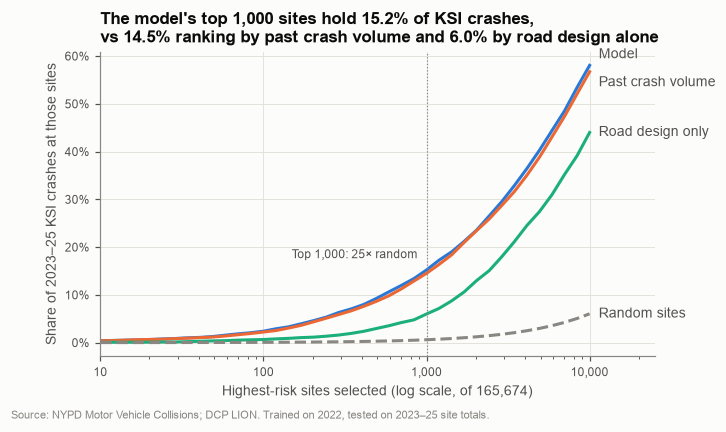

In [6]:
fig, ax = plt.subplots(figsize=(FULL_WIDTH, 3.6))
styles = {
    "Model": (MODEL, "-"),
    "Past crash volume": (COMPARISON, "-"),
    "Road design only": (THIRD, "-"),
    "Random sites": (MUTED, "--"),
}
# The model and past-crash-volume lines end almost together; nudge their labels apart.
nudge = {"Model": 7, "Past crash volume": -7}
for name, (color, ls) in styles.items():
    ax.plot(curves.index, curves[name], color=color, linestyle=ls)
    ax.annotate(name, (curves.index[-1], curves[name].iloc[-1]), xytext=(6, nudge.get(name, 0)),
                textcoords="offset points", va="center", color=INK_2)
ax.axvline(1000, color=MUTED, linewidth=0.8, linestyle=":")
ax.annotate(f"Top 1,000: {lift:.0f}× random", (1000, standard["top1000"]),
            xytext=(-6, 6), textcoords="offset points", ha="right", va="bottom", color=INK_2, fontsize=8)
ax.set(xscale="log", xlim=(10, 25_000), xlabel=f"Highest-risk sites selected (log scale, of {n_sites:,})",
       ylabel="Share of 2023–25 KSI crashes at those sites")
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.xaxis.set_minor_formatter(NullFormatter())
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_title(f"The model's top 1,000 sites hold {standard['top1000']:.1%} of KSI crashes,\n"
             f"vs {volume['top1000']:.1%} ranking by past crash volume and {road_only['top1000']:.1%} by road design alone")
source(fig, SOURCE + " Trained on 2022, tested on 2023–25 site totals.")
save(fig, "2_capture_vs_random")

**Takeaways.** Ranking sites by past crash volume, roughly what DOT already weighs, gets most of the way there; the gap between the blue and orange lines is what the model adds by weighting crashes by severity, road user and type and adding road design. The more useful result for prevention is the road-design-only model: with no crash history at all, it still finds about ten times more KSI crashes than random selection, so it can flag dangerous designs before the crashes accumulate.

## 4. What carries KSI risk?

In [7]:
# Crash counts enter as log(1 + count), so their rows show the effect of doubling.
# Every intersection site has 3+ legs and every mid-block site has the mid-block flag, and
# block length enters as log(feet), so single coefficients would compare against a 1-ft
# block. Intersections are shown against a typical block instead: 250 ft (the median),
# away from intersections. Each row is a linear combination of coefficients, exponentiated.
DOUBLE = np.log(2)
TYPICAL_BLOCK = {"midblock": 1, "log_block_length": np.log(250)}
GROUPS = {
    "Crash history, past 3 years (per doubling)": {
        "Property-damage-only crashes": {"log1p_pdo_lag3": DOUBLE},
        "Injury crashes (not KSI)": {"log1p_injury_nonsevere_lag3": DOUBLE},
        "KSI crashes without a death": {"log1p_ksi_nonfatal_lag3": DOUBLE},
        "Fatal crashes": {"log1p_fatal_lag3": DOUBLE},
        "Pedestrians hurt": {"log1p_ped_injured_lag3": DOUBLE},
        "Cyclists hurt": {"log1p_cyc_injured_lag3": DOUBLE},
        "No crashes at all (vs some)": {"no_history": 1},
    },
    "Crash types, past 3 years (per doubling)": {
        "Red-light running": {"log1p_rlr_lag3": DOUBLE},
        "Rear-end": {"log1p_rear_end_lag3": DOUBLE},
        "Angle": {"log1p_angle_lag3": DOUBLE},
    },
    "Site (vs a 250 ft block away from intersections)": {
        "3-way intersection": {"legs_3": 1, **{k: -v for k, v in TYPICAL_BLOCK.items()}},
        "4-way intersection": {"legs_4": 1, **{k: -v for k, v in TYPICAL_BLOCK.items()}},
        "5+-way intersection": {"legs_5plus": 1, **{k: -v for k, v in TYPICAL_BLOCK.items()}},
        "Block twice as long": {"log_block_length": DOUBLE},
        "Each extra intersection within 100 ft": {"n_intersections": 1},
    },
    "Road design": {
        "Each extra travel lane": {"lanes": 1},
        "Each 10 ft of street width": {"width_10ft": 1},
        "Each 1 ft of lane width": {"lane_width_ft": 1},
        "Speed limit 20 mph or less (vs 25)": {"speed_20_or_less": 1},
        "Speed limit 30–35 mph (vs 25)": {"speed_30_35": 1},
        "Speed limit 40+ mph (vs 25)": {"speed_40_plus": 1},
        "One-way street": {"one_way": 1},
        "Highway or ramp": {"highway": 1},
        "Truck route": {"truck_route": 1},
    },
}
params, cov = model.result_.params, model.result_.cov_params()


def rate_ratio(weights):
    w = pd.Series(0.0, index=params.index)
    for name, value in weights.items():
        w[name] += value
    estimate, se = w @ params, np.sqrt(w @ cov @ w)
    return np.exp([estimate, estimate - 1.96 * se, estimate + 1.96 * se])


coefs = pd.DataFrame(
    [(group, label, *rate_ratio(w)) for group, rows in GROUPS.items() for label, w in rows.items()],
    columns=["group", "variable", "ratio", "ci_low", "ci_high"],
)
coefs.round(3)

,group,variable,ratio,ci_low,ci_high
0,"Crash history, past 3 years (per doubling)",Property-damage-only crashes,1.382,1.279,1.493
1,"Crash history, past 3 years (per doubling)",Injury crashes (not KSI),1.427,1.324,1.538
2,"Crash history, past 3 years (per doubling)",KSI crashes without a death,1.078,0.996,1.166
3,"Crash history, past 3 years (per doubling)",Fatal crashes,0.938,0.755,1.166
4,"Crash history, past 3 years (per doubling)",Pedestrians hurt,1.014,0.954,1.077
5,"Crash history, past 3 years (per doubling)",Cyclists hurt,1.202,1.130,1.278
6,"Crash history, past 3 years (per doubling)",No crashes at all (vs some),0.192,0.146,0.254
7,"Crash types, past 3 years (per doubling)",Red-light running,0.924,0.860,0.992
8,"Crash types, past 3 years (per doubling)",Rear-end,1.030,0.959,1.107
9,"Crash types, past 3 years (per doubling)",Angle,0.945,0.883,1.011


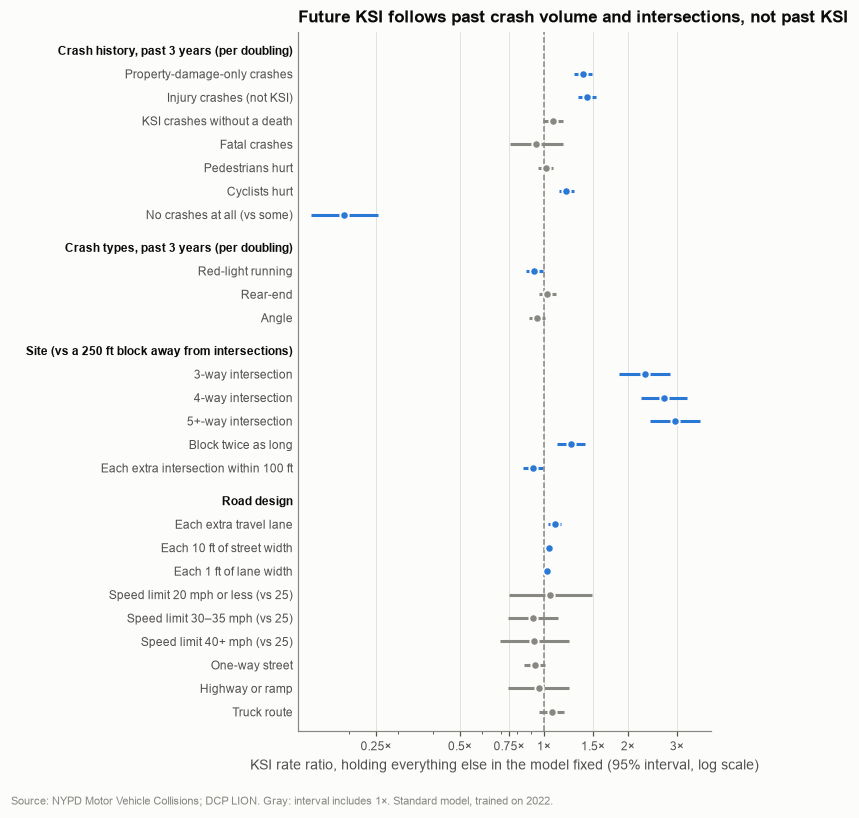

In [8]:
fig, ax = plt.subplots(figsize=(FULL_WIDTH, 7.2))
y, labels, ypos = 0, [], []
for group, rows in coefs.groupby("group", sort=False):
    labels.append((y, group, True))  # group header row, no point
    y += 1
    for _, row in rows.iterrows():
        clear = row["ci_low"] > 1 or row["ci_high"] < 1
        color = MODEL if clear else MUTED
        ax.hlines(y, row["ci_low"], row["ci_high"], color=color, linewidth=2)
        ax.scatter(row["ratio"], y, color=color, s=30, zorder=3, edgecolor=SURFACE, linewidth=1.2)
        labels.append((y, row["variable"], False))
        y += 1
    y += 0.4
ax.axvline(1, color=MUTED, linestyle="--", linewidth=1)
ax.set_yticks([pos for pos, _, _ in labels], [text for _, text, _ in labels])
for tick, (_, _, is_group) in zip(ax.get_yticklabels(), labels):
    if is_group:
        tick.set_fontweight("bold")
        tick.set_color(INK)
ax.tick_params(axis="y", length=0)
ax.set_ylim(y - 0.6, -0.8)
ax.grid(axis="y", visible=False)
ax.set_xscale("log")
low, high = coefs["ci_low"].min() * 0.9, coefs["ci_high"].max() * 1.1
ax.set_xlim(low, high)
ax.set_xticks([t for t in [0.25, 0.5, 0.75, 1, 1.5, 2, 3, 5, 8] if low <= t <= high])
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}×"))
ax.xaxis.set_minor_formatter(NullFormatter())
ax.set(xlabel="KSI rate ratio, holding everything else in the model fixed (95% interval, log scale)")
ax.set_title("Future KSI follows past crash volume and intersections, not past KSI")
fig.tight_layout()
source(fig, SOURCE + " Gray: interval includes 1×. Standard model, trained on 2022.")
save(fig, "3_risk_factors")

**Reading the chart.** Each point is how much expected KSI changes with that variable when everything else in the model is held fixed; blue intervals exclude "no effect" (1×). Crash-history rows show the effect of doubling that count. Past KSI and fatal crashes add little once total crash volume is known: they are rare, so their counts are noisy, while injury and property-damage crashes show where conflicts happen often. Crash types add nothing beyond volume. These are associations, not causal effects: busy streets tend to be wide, multi-lane truck routes, and there is no traffic-volume data yet (#35).

## 5. Are the predicted numbers right?

In [9]:
cal = calibration_table(totals["ksi"], totals["pred"], ValidationConfig().calibration_quantiles)
cal[["q_low", "q_high", "n", "mean_pred", "mean_obs", "obs_low", "obs_high"]].round(3)

,q_low,q_high,n,mean_pred,mean_obs,obs_low,obs_high
bin,,,,,,,
0,0.000,0.500,82837,0.002,0.002,0.002,0.002
1,0.500,0.800,49703,0.015,0.018,0.017,0.019
2,0.800,0.900,16567,0.062,0.079,0.074,0.083
3,0.900,0.950,8284,0.125,0.180,0.171,0.190
4,0.950,0.980,4970,0.235,0.347,0.331,0.364
5,0.980,0.990,1657,0.409,0.551,0.516,0.588
6,0.990,0.995,828,0.607,0.752,0.694,0.814
7,0.995,0.999,663,0.993,1.175,1.094,1.260
8,0.999,1.000,165,2.387,1.891,1.687,2.113


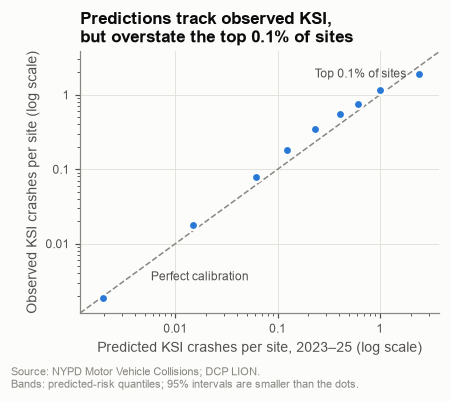

In [10]:
fig, ax = plt.subplots(figsize=(FULL_WIDTH * 0.62, 3.4))
lims = (cal["mean_pred"].min() * 0.6, max(cal["obs_high"].max(), cal["mean_pred"].max()) * 1.6)
ax.plot(lims, lims, color=MUTED, linestyle="--", linewidth=1)
ax.annotate("Perfect calibration", (lims[0] * 4, lims[0] * 4), xytext=(6, -2), textcoords="offset points",
            ha="left", va="top", color=INK_2, fontsize=8)
ax.vlines(cal["mean_pred"], cal["obs_low"], cal["obs_high"], color=MODEL, linewidth=2)
ax.scatter(cal["mean_pred"], cal["mean_obs"], color=MODEL, s=36, zorder=3, edgecolor=SURFACE, linewidth=1.5)
top = cal.iloc[-1]
ax.annotate("Top 0.1% of sites", (top["mean_pred"], top["mean_obs"]), xytext=(-8, 0),
            textcoords="offset points", ha="right", va="center", color=INK_2, fontsize=8)
ax.set(xscale="log", yscale="log", xlim=lims, ylim=lims,
       xlabel="Predicted KSI crashes per site, 2023–25 (log scale)",
       ylabel="Observed KSI crashes per site (log scale)")
for axis in (ax.xaxis, ax.yaxis):
    axis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
    axis.set_minor_formatter(NullFormatter())
ax.set_title("Predictions track observed KSI,\nbut overstate the top 0.1% of sites")
fig.tight_layout()
source(fig, SOURCE + "\nBands: predicted-risk quantiles; 95% intervals are smaller than the dots.")
save(fig, "4_calibration")

## 6. Why road data must match the year: protected bike lanes

In [11]:
snapshot = add_roadway_features(panel.drop(columns=FEATURE_SETS["road"] + FEATURE_SETS["bike"]),
                                load_roadway_features(sites))
leak = []
for name, data in [("26c snapshot (2026)", snapshot), ("Year-matched release", panel)]:
    for feature in FEATURE_SETS["bike"]:
        _, _, fit = run(STANDARD + [feature], data)
        row = fit.coefficients().loc[feature, ["ratio", "ci_low", "ci_high"]]
        share = data.loc[data["year"] == min(TEST_YEARS), feature].mean()
        leak.append({"data": name, "feature": feature, "share_of_sites": share, **row})
leak = pd.DataFrame(leak)
leak.round(3)

,data,feature,share_of_sites,ratio,ci_low,ci_high
0,26c snapshot (2026),bike_lane,0.213,1.199,1.095,1.313
1,26c snapshot (2026),protected_bike_lane,0.065,1.129,0.995,1.280
2,Year-matched release,bike_lane,0.193,1.180,1.076,1.295
3,Year-matched release,protected_bike_lane,0.048,1.030,0.881,1.205


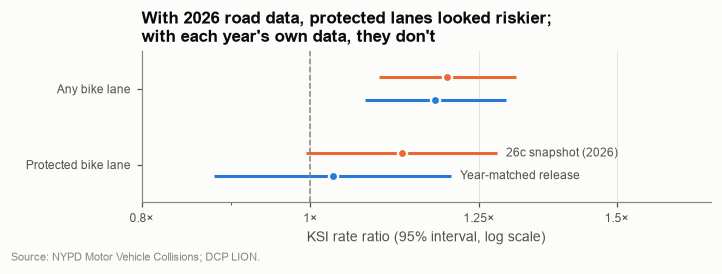

In [12]:
fig, ax = plt.subplots(figsize=(FULL_WIDTH, 2.4))
names = {"protected_bike_lane": "Protected bike lane", "bike_lane": "Any bike lane"}
for offset, (name, color) in zip([0.15, -0.15], [("26c snapshot (2026)", COMPARISON), ("Year-matched release", MODEL)]):
    d = leak[leak["data"] == name].set_index("feature").loc[list(names)]
    yy = np.arange(len(names)) + offset
    ax.hlines(yy, d["ci_low"], d["ci_high"], color=color, linewidth=2)
    ax.scatter(d["ratio"], yy, color=color, s=36, zorder=3, edgecolor=SURFACE, linewidth=1.5)
    ax.annotate(name, (d["ci_high"].iloc[0], yy[0]), xytext=(6, 0), textcoords="offset points",
                va="center", color=INK_2, fontsize=8)
ax.axvline(1, color=MUTED, linestyle="--", linewidth=1)
ax.set_yticks(np.arange(len(names)), list(names.values()))
ax.set_ylim(-0.5, len(names) - 0.5)
ax.grid(axis="y", visible=False)
ax.set_xscale("log")
ax.set_xticks([0.8, 1, 1.25, 1.5])
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}×"))
ax.xaxis.set_minor_formatter(NullFormatter())
ax.set(xlabel="KSI rate ratio (95% interval, log scale)")
ax.set_xlim(0.8, 1.7)
ax.set_title("With 2026 road data, protected lanes looked riskier;\nwith each year's own data, they don't")
fig.tight_layout()
source(fig)
save(fig, "5_lion_leakage")

**Takeaways.** A single 2026 LION snapshot marks protected lanes that didn't exist yet: about a quarter of the snapshot's protected-lane sites had no protected lane at the start of 2023. Lanes are often built where serious crashes happened, so the snapshot makes them look riskier. With the release in effect each year, the protected-lane effect is 1.0×. That isn't evidence that lanes don't help: this compares streets with and without lanes, and lanes go where danger is. "Any bike lane" stays near 1.2× under both versions, which most likely reflects cyclist volume (#51). Bike features are left out of the standard model.

## 7. Everything we tried

In [13]:
H, S, T, R, P = F["history"], F["site"], F["crash_types"], F["road"], F["temporal"]
specs = {
    "Past crash volume only (rank by last 3 years' crashes)": lambda: HistoryRanker("crashes_lag3", 3),
    "Past KSI only (rank by last 3 years' KSI)": lambda: HistoryRanker("ksi_lag3", 3),
    "Crash history": H,
    "+ site type (mid-block, block length)": H + S,
    "+ crash types (red-light running, rear-end, angle)": H + S + T,
    "+ LION road features": H + S + R,
    "+ no-history flag (no crashes in 3 years)": H + S + ["no_history"],
    "+ recent change in crashes": H + S + ["recent_change", "no_history"],
    "+ night share": H + S + ["night_share", "no_history"],
    "+ weekend share": H + S + ["weekend_share", "no_history"],
    "+ road + any bike lane": H + S + R + ["bike_lane"],
    "+ road + protected bike lane": H + S + R + ["protected_bike_lane"],
    "Standard model (history, site, crash types, road, no-history flag)": STANDARD,
    "Road design only (no crash history)": ROAD_ONLY,
}
scores = {name: run(features)[0] for name, features in specs.items()}
base = run(H + S)[0]["deviance"]
tried = pd.DataFrame(
    {
        "Top 100": [v["top100"] for v in scores.values()],
        "Top 1,000": [v["top1000"] for v in scores.values()],
        # a ranking has no count scale, so deviance doesn't apply to the past-count rankings
        "Deviance vs history + site": [
            np.nan if name.startswith("Past") else v["deviance"] / base - 1 for name, v in scores.items()
        ],
    },
    index=list(scores),
)
random_row = pd.DataFrame({"Top 100": [100 / n_sites], "Top 1,000": [1000 / n_sites]}, index=["Random sites"])
tried = pd.concat([random_row, tried])
verdict = {
    "Random sites": "Comparison",
    "Past crash volume only (rank by last 3 years' crashes)": "Simple benchmark",
    "Past KSI only (rank by last 3 years' KSI)": "Simple benchmark",
    "Crash history": "Kept",
    "+ site type (mid-block, block length)": "Kept",
    "+ crash types (red-light running, rear-end, angle)": "Kept (small)",
    "+ LION road features": "Kept",
    "+ no-history flag (no crashes in 3 years)": "Kept",
    "+ road + any bike lane": "Dropped: likely cyclist volume (#51)",
    "+ road + protected bike lane": "Dropped: no effect once year-matched (#48)",
    "Standard model (history, site, crash types, road, no-history flag)": "Standard",
    "Road design only (no crash history)": "Screening without history",
}
# Each temporal feature is fit with the no-history flag, so judge it by what it adds beyond that.
flag_only = scores["+ no-history flag (no crashes in 3 years)"]["deviance"]
for name in ["+ recent change in crashes", "+ night share", "+ weekend share"]:
    gain = scores[name]["deviance"] / flag_only - 1
    verdict[name] = f"Kept (small: {gain:+.1%} beyond the flag)" if gain < -0.005 else f"Dropped: no gain beyond the flag ({gain:+.1%})"
tried["Verdict"] = tried.index.map(verdict)
tried.style.format({"Top 100": "{:.1%}", "Top 1,000": "{:.1%}", "Deviance vs history + site": "{:+.1%}"}, na_rep="–")

,Top 100,"Top 1,000",Deviance vs history + site,Verdict
Random sites,0.1%,0.6%,–,Comparison
Past crash volume only (rank by last 3 years' crashes),2.2%,14.5%,–,Simple benchmark
Past KSI only (rank by last 3 years' KSI),2.0%,11.1%,–,Simple benchmark
Crash history,2.5%,14.8%,+6.2%,Kept
"+ site type (mid-block, block length)",2.6%,14.7%,+0.0%,Kept
"+ crash types (red-light running, rear-end, angle)",2.5%,14.6%,-0.4%,Kept (small)
+ LION road features,2.4%,15.2%,-1.9%,Kept
+ no-history flag (no crashes in 3 years),2.6%,15.1%,-2.5%,Kept
+ recent change in crashes,2.6%,14.9%,-2.8%,Dropped: no gain beyond the flag (-0.3%)
+ night share,2.6%,15.0%,-2.5%,Dropped: no gain beyond the flag (-0.0%)


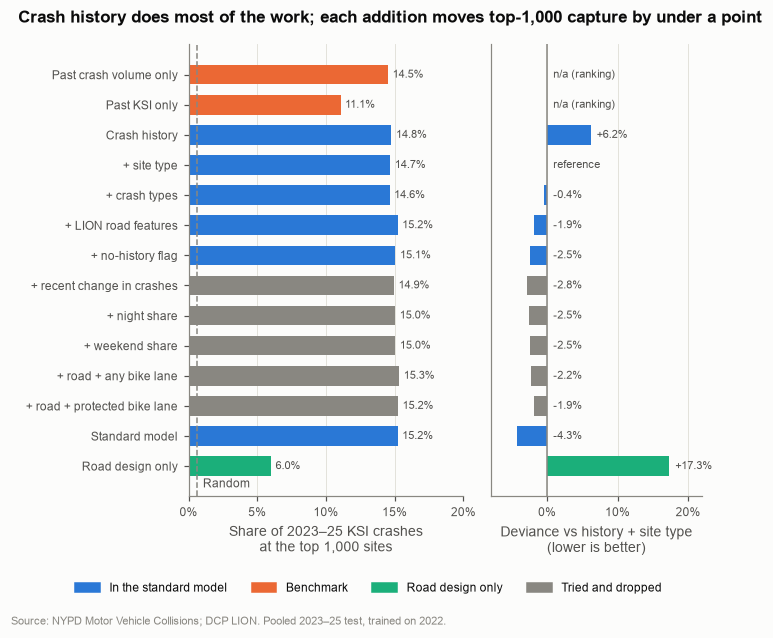

In [14]:
def category(verdict):
    if verdict.startswith("Dropped"):
        return "Tried and dropped"
    if verdict in ("Comparison", "Simple benchmark"):
        return "Benchmark"
    if verdict.startswith("Screening"):
        return "Road design only"
    return "In the standard model"


CATEGORY_COLORS = {
    "In the standard model": MODEL,
    "Benchmark": COMPARISON,
    "Road design only": THIRD,
    "Tried and dropped": MUTED,
}
rows = tried.drop(index="Random sites")
colors = [CATEGORY_COLORS[category(v)] for v in rows["Verdict"]]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(FULL_WIDTH, 5.2), sharey=True,
                               gridspec_kw={"width_ratios": [1.3, 1]})
y = np.arange(len(rows))
ax1.barh(y, rows["Top 1,000"], color=colors, height=0.65)
ax1.axvline(1000 / n_sites, color=MUTED, linestyle="--", linewidth=1)
ax1.annotate("Random", (1000 / n_sites, len(rows) - 0.4), xytext=(4, 0), textcoords="offset points",
             color=INK_2, fontsize=8, va="center")
for yy, value in zip(y, rows["Top 1,000"]):
    ax1.annotate(f"{value:.1%}", (value, yy), xytext=(3, 0), textcoords="offset points",
                 va="center", color=INK_2, fontsize=7.5)
ax1.set_yticks(y, [name.split(" (")[0] for name in rows.index])  # full names in the table
ax1.invert_yaxis()
ax1.grid(axis="y", visible=False)
ax1.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax1.set(xlabel="Share of 2023–25 KSI crashes\nat the top 1,000 sites", xlim=(0, 0.2))

deviance = rows["Deviance vs history + site"]
ax2.barh(y, deviance.fillna(0), color=colors, height=0.65)
for yy, name, value in zip(y, rows.index, deviance):
    if np.isnan(value):
        text = "n/a (ranking)"
    elif name.startswith("+ site type"):
        text = "reference"
    else:
        text = f"{value:+.1%}"
    # labels sit right of zero (or of a positive bar) so they never collide with the axis
    ax2.annotate(text, (max(0 if np.isnan(value) else value, 0), yy), xytext=(4, 0),
                 textcoords="offset points", ha="left", va="center", color=INK_2, fontsize=7.5)
ax2.axvline(0, color=MUTED, linewidth=1)
ax2.grid(axis="y", visible=False)
ax2.tick_params(axis="y", length=0)
ax2.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax2.set(xlabel="Deviance vs history + site type\n(lower is better)", xlim=(-0.08, 0.22))
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in CATEGORY_COLORS.values()]
fig.legend(handles, CATEGORY_COLORS.keys(), loc="lower center", ncols=4, bbox_to_anchor=(0.5, -0.06))
fig.suptitle("Crash history does most of the work; each addition moves top-1,000 capture by under a point",
             x=0.01, ha="left", fontweight="bold", fontsize=11)
fig.tight_layout()
source(fig, SOURCE + " Pooled 2023–25 test, trained on 2022.")
save(fig, "6_everything_tried")

Top-k capture: share of all 2023–25 KSI crashes at the model's top 100 or 1,000 sites (higher is better). Deviance: fit across every site, relative to history + site type (lower is better). Top-100 capture moves by chance between models (about ±0.3 points), so small differences there aren't meaningful.

**Site definitions.** Changing the sites changes which crashes are counted, so these are compared on the share of *all* geocoded 2023–25 KSI crashes captured.

In [15]:
geo_ksi = int(crashes.loc[crashes["crash_date"].dt.year.isin(TEST_YEARS), "ksi"].sum())
site_rows = []
for name, cfg in [
    ("Crash clusters, 100 ft (Q1, Q2)", SiteConfig(source="crashes", build_end="2023-01-01")),
    ("LION intersections only (KSI v2)", SiteConfig(midblock=False)),
    ("LION intersections + mid-block (standard)", SiteConfig()),
]:
    p, _, s = load_panel(site_config=cfg)
    features = H + [c for c in S if c in p and p[c].nunique() > 1]
    site_scores, site_totals, _ = run(features, p)
    captured = site_scores["top1000"] * site_totals["ksi"].sum()
    site_rows.append({"Sites": name, "Number of sites": len(s),
                      "KSI crashes covered": site_totals["ksi"].sum() / geo_ksi,
                      "Top 1,000 capture (of all KSI)": captured / geo_ksi})
pd.DataFrame(site_rows).set_index("Sites").style.format(
    {"Number of sites": "{:,}", "KSI crashes covered": "{:.0%}", "Top 1,000 capture (of all KSI)": "{:.1%}"})

,Number of sites,KSI crashes covered,"Top 1,000 capture (of all KSI)"
Sites,,,
"Crash clusters, 100 ft (Q1, Q2)","86,167",96%,14.8%
LION intersections only (KSI v2),"46,896",80%,14.3%
LION intersections + mid-block (standard),"165,674",99%,14.5%


## 8. Limitations and next steps

**Limitations**
- **Crash history does most of the work**, and DOT already uses it. The model's added value is ranking sites consistently, and the road-only model's ability to screen sites without history.
- **No exposure.** Without traffic, pedestrian or cyclist volumes, "risky" road features partly mean "busy" (#35, #51).
- **Associations, not effects.** None of the rate ratios says what would happen if a street were redesigned.
- **Sites come from LION 26c** and each year's road features from one release, so changes within a year are missed.
- **Speed cameras** are geocoded to "street @ cross street", so mid-block cameras land on intersections (#45). Cameras aren't model features.

**Next steps**
- **Site context:** land use (MapPLUTO, #33), Census equity covariates (#34), traffic volume (#35), cyclist volume (#51).
- **From risk to placement.** Nguyen (2026) optimizes speed-camera allocation across borough-weeks with a learned simulator. Its safety gain depends on the estimated camera effect and disappears when that effect is removed, and DOT notes boroughs are too coarse for placement. A site-level version needs two pieces: predicted risk (this model) and the *camera effect for that kind of site*, estimated by comparing sites before and after camera activation against similar sites without cameras (cf. Stagoff-Belfort et al. 2025). Expected benefit = risk × effect is the quantity DOT can't get from crash history alone.

*References.* Nguyen, H. Q. (2026). Learning to allocate automated speed enforcement. *Case Studies on Transport Policy* 25, 101855. Stagoff-Belfort, A., Ben-Menachem, J., & Beck, B. (2025). Can speed cameras make streets safer? *PNAS* 122(50).